# Notebook 17 — Controlled Feature Ablation for Dengue Forecasting
**Research objective:** Quantify whether historical dengue counts, weather, seasonality, temporal engineering and population add useful one-month-ahead prediction information. This is a **validation-only** follow-up to Notebooks 11–16.

**Protocol:** train target dates through December 2021; validation target dates January 2022–December 2023. **Never load the 2024 test split here.** Use identical district–target-month observations for all comparisons, including the population model (2014+ common cohort). The original 2010–2021 full-history model is *not* directly comparable to these shorter-cohort ablations.

These are *new training experiments*, not post-hoc feature permutation. Outcomes will be computed locally; no numbers are assumed in advance.

## 1. Setup and dependencies
Run Notebook 12 first. TensorFlow, pandas, NumPy, scikit-learn and matplotlib are required. Set `SEEDS=(42,)` for a quick exploratory run; use three or more seeds for a stronger comparison.

In [1]:
from pathlib import Path
import json, os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display

SEED=42
ROOT=next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data'/'final'/'model_inputs').is_dir()),None)
if ROOT is None: raise FileNotFoundError('Run Notebook 12 and open the Dengue_Project folder or notebooks/ in VS Code.')
INP=ROOT/'data'/'final'/'model_inputs'; FINAL=ROOT/'data'/'final'
MODELS=ROOT/'models'; TABLES=ROOT/'results'/'tables'; FIGS=ROOT/'results'/'figures'; METRICS=ROOT/'results'/'metrics'
for folder in (TABLES,FIGS,METRICS):folder.mkdir(parents=True,exist_ok=True)
try:
 import tensorflow as tf
except ImportError as e: raise ImportError('Install tensorflow in your active .venv') from e
print('Project:',ROOT,'| TensorFlow:',tf.__version__)

def load_part(variant,part):
 path=INP/f'{variant}_{part}.npz'; meta_path=INP/f'{variant}_{part}_metadata.csv'
 if not path.is_file() or not meta_path.is_file():raise FileNotFoundError(f'Missing {path} or {meta_path}. Run Notebook 12.')
 with np.load(path,allow_pickle=False) as p:
  X=p['X'].astype(np.float32); y=p['y_raw'].astype(np.float64); ylog=p['y_log1p'].astype(np.float32); names=p['feature_names'].tolist()
 meta=pd.read_csv(meta_path,parse_dates=['target_date','feature_date','sequence_start_date'])
 assert len(X)==len(y)==len(ylog)==len(meta) and np.isfinite(X).all()
 assert meta['partition'].eq(part).all() and np.allclose(np.log1p(y),ylog,atol=1e-4)
 return X,y,ylog,names,meta

def cases(logpred):
 return np.maximum(0,np.expm1(np.clip(np.asarray(logpred,dtype=float).reshape(-1),-20,20)))
def scores(actual,pred):
 a=np.asarray(actual,float);p=np.asarray(pred,float)
 return {'MAE_cases':float(mean_absolute_error(a,p)), 'RMSE_cases':float(np.sqrt(mean_squared_error(a,p))),
         'bias_cases':float(np.mean(p-a)), 'WAPE_percent':float(100*np.sum(np.abs(a-p))/np.sum(a)) if np.sum(a)>0 else np.nan}
def build_lstm(input_shape,lr=.001,dropout=.2):
 m=tf.keras.Sequential([tf.keras.layers.Input(shape=input_shape),tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(16,activation='relu'),tf.keras.layers.Dropout(float(dropout)),tf.keras.layers.Dense(1)])
 m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=float(lr)),loss='mse')
 return m

def train_net(Xtr,ytr,Xv,yv,seed,lr=.001,dropout=.2,batch=32,epochs=40,patience=6):
 tf.keras.backend.clear_session();tf.keras.utils.set_random_seed(int(seed))
 m=build_lstm(Xtr.shape[1:],lr,dropout)
 hist=m.fit(Xtr,ytr,validation_data=(Xv,yv),epochs=int(epochs),batch_size=int(batch),
     shuffle=False,verbose=0,callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=int(patience),restore_best_weights=True)])
 return m,len(hist.history['loss'])

Project: d:\Dengue_Project | TensorFlow: 2.21.0


## 2. Load population and weather-only inputs; align the exact same cohort
The population dataset starts in 2014. We therefore match **both** datasets on district and target month to ensure any observed population effect is not confounded by different training dates. Both versions were scaled with train-only statistics in Notebook 12.

In [2]:
w={p:load_part('weather_only',p) for p in ('train','validation')}
p={part:load_part('with_population',part) for part in ('train','validation')}
for part in ('train','validation'):
 wx,wy,wl,wn,wm=w[part]; px,py,pl,pn,pm=p[part]
 assert len(pm)==len(px)
 wk=pd.MultiIndex.from_frame(wm[['administrative_district','target_date']]);pk=pd.MultiIndex.from_frame(pm[['administrative_district','target_date']])
 indices=wk.get_indexer(pk)
 assert (indices>=0).all(), 'Population target keys must be contained in weather-only target keys'
 assert np.allclose(wy[indices],py,atol=.01)
 assert np.array_equal(wm.iloc[indices]['target_date'].to_numpy(),pm['target_date'].to_numpy())
 w[part]=(wx[indices],wy[indices],wl[indices],wn,wm.iloc[indices].reset_index(drop=True))
 print(part,':',len(pm),'matched examples |',pm.target_date.min().date(),'to',pm.target_date.max().date())
assert p['validation'][4]['target_date'].dt.year.isin([2022,2023]).all()
assert p['train'][4]['target_date'].max()<=pd.Timestamp('2021-12-01')
print('Matched cohort: no 2024 data accessed')

train : 2250 matched examples | 2014-07-01 to 2021-12-01
validation : 600 matched examples | 2022-01-01 to 2023-12-01
Matched cohort: no 2024 data accessed


## 3. Define feature families and experimental groups
`basic` uses contemporaneous dengue/weather and target-month sin/cos only; `engineered` includes lags and rolling summaries. Weather-only and dengue-only groups retain seasonality to avoid removing calendar context from just one group. Population is tested only against the **same common cohort**.

In [3]:
weather_names=w['train'][3];pop_names=p['train'][3]
assert pop_names==weather_names+['population']
dengue=[i for i,n in enumerate(weather_names) if n.startswith('dengue_cases')]
weather=[i for i,n in enumerate(weather_names) if n.startswith(('temperature_mean_c','humidity_mean_percent','rainfall_total_mm','wind_speed_mean_kmh'))]
season=[i for i,n in enumerate(weather_names) if n.startswith('target_month_')]
assert sorted(dengue+weather+season)==list(range(len(weather_names)))
basic_names=['dengue_cases','temperature_mean_c','humidity_mean_percent','rainfall_total_mm','wind_speed_mean_kmh','target_month_sin','target_month_cos']
experiments={
 'dengue_history_plus_season':('weather_only',dengue+season),
 'weather_plus_season':('weather_only',weather+season),
 'basic_combined_no_engineering':('weather_only',[weather_names.index(k) for k in basic_names]),
 'engineered_dengue_weather_season':('weather_only',list(range(len(weather_names)))),
 'engineered_plus_population':('with_population',list(range(len(pop_names))))}
for label,(variant,idx) in experiments.items():
 print(f'{label:40s} {variant:16s} {len(idx):2d} predictors')
assert all(len(idx)>0 for variant,idx in experiments.values())

dengue_history_plus_season               weather_only      9 predictors
weather_plus_season                      weather_only     26 predictors
basic_combined_no_engineering            weather_only      7 predictors
engineered_dengue_weather_season         weather_only     33 predictors
engineered_plus_population               with_population  34 predictors


## 4. Run controlled ablation experiments
Each group is **retrained from scratch**, with a consistent LSTM(32)–Dense(16) architecture, learning rate 0.001, dropout 0.2, early stopping, and identical training/validation target months. Validation is used for early stopping, so these are exploratory validation results, not an independent generalization estimate. Runtime depends on hardware.

In [4]:
SEEDS=(42,123,2026) # change to (42,) for a quick smoke test
MAX_EPOCHS=40;PATIENCE=6
rows=[]; predictions=[]
for name,(variant,indices) in experiments.items():
 xt,yt,ytlog,names,mt=(w if variant=='weather_only' else p)['train']
 xv,yv,yvlog,_,mv=(w if variant=='weather_only' else p)['validation']
 for seed in SEEDS:
  model,epochs=train_net(xt[:,:,indices],ytlog,xv[:,:,indices],yvlog,seed,epochs=MAX_EPOCHS,patience=PATIENCE)
  pred=cases(model.predict(xv[:,:,indices],verbose=0))
  result={'experiment':name,'variant':variant,'seed':seed,'n_features':len(indices),'n_train':len(yt),'n_val':len(yv),'epochs':epochs,**scores(yv,pred)}
  rows.append(result)
  t=mv[['administrative_district','target_date']].copy();t['experiment']=name;t['seed']=seed;t['actual_cases']=yv;t['predicted_cases']=pred
  predictions.append(t)
  print(name,'seed',seed,'MAE',round(result['MAE_cases'],2),'RMSE',round(result['RMSE_cases'],2))
  del model
results=pd.DataFrame(rows);predictions=pd.concat(predictions,ignore_index=True)
display(results)


dengue_history_plus_season seed 42 MAE 80.53 RMSE 171.75
dengue_history_plus_season seed 123 MAE 81.18 RMSE 174.08
dengue_history_plus_season seed 2026 MAE 81.55 RMSE 176.15
weather_plus_season seed 42 MAE 135.75 RMSE 272.05
weather_plus_season seed 123 MAE 140.1 RMSE 279.63
weather_plus_season seed 2026 MAE 142.1 RMSE 282.98
basic_combined_no_engineering seed 42 MAE 79.25 RMSE 171.49
basic_combined_no_engineering seed 123 MAE 77.97 RMSE 165.69
basic_combined_no_engineering seed 2026 MAE 78.59 RMSE 163.51
engineered_dengue_weather_season seed 42 MAE 85.55 RMSE 173.36
engineered_dengue_weather_season seed 123 MAE 83.08 RMSE 168.94
engineered_dengue_weather_season seed 2026 MAE 81.73 RMSE 167.59
engineered_plus_population seed 42 MAE 85.26 RMSE 185.08
engineered_plus_population seed 123 MAE 81.29 RMSE 165.86
engineered_plus_population seed 2026 MAE 82.0 RMSE 170.04


,experiment,variant,seed,n_features,n_train,n_val,epochs,MAE_cases,RMSE_cases,bias_cases,WAPE_percent
0,dengue_history_plus_season,weather_only,42,9,2250,600,40,80.527713,171.752821,-36.070155,45.534104
1,dengue_history_plus_season,weather_only,123,9,2250,600,40,81.182789,174.075002,-42.094493,45.904514
2,dengue_history_plus_season,weather_only,2026,9,2250,600,37,81.547504,176.147730,-38.584773,46.110741
3,weather_plus_season,weather_only,42,26,2250,600,27,135.745732,272.053130,-118.926406,76.756933
4,weather_plus_season,weather_only,123,26,2250,600,19,140.095779,279.626046,-131.724003,79.216651
5,weather_plus_season,weather_only,2026,26,2250,600,12,142.100115,282.978861,-136.287337,80.349996
6,basic_combined_no_engineering,weather_only,42,7,2250,600,38,79.248056,171.489011,-54.289920,44.810526
7,basic_combined_no_engineering,weather_only,123,7,2250,600,40,77.967177,165.694820,-47.162685,44.086258
8,basic_combined_no_engineering,weather_only,2026,7,2250,600,40,78.585336,163.506729,-48.883604,44.435794
9,engineered_dengue_weather_season,weather_only,42,33,2250,600,34,85.547797,173.361796,-51.673350,48.372692


## 5. Summarize and visualize validation results
Lower MAE/RMSE is better. Report per-seed results as well as means and standard deviations; with only three seeds, uncertainty estimates are still preliminary.

,experiment,n_seeds,MAE_mean,MAE_sd,RMSE_mean,RMSE_sd,bias_mean
0,basic_combined_no_engineering,3,78.600190,0.640569,166.896853,4.124666,-50.112070
1,dengue_history_plus_season,3,81.086002,0.516739,173.991851,2.198634,-38.916474
3,engineered_plus_population,3,82.851227,2.118971,173.660306,10.106052,-33.096186
2,engineered_dengue_weather_season,3,83.452708,1.936565,169.962879,3.019350,-44.389951
4,weather_plus_season,3,139.313875,3.248550,278.219345,5.597053,-128.979249


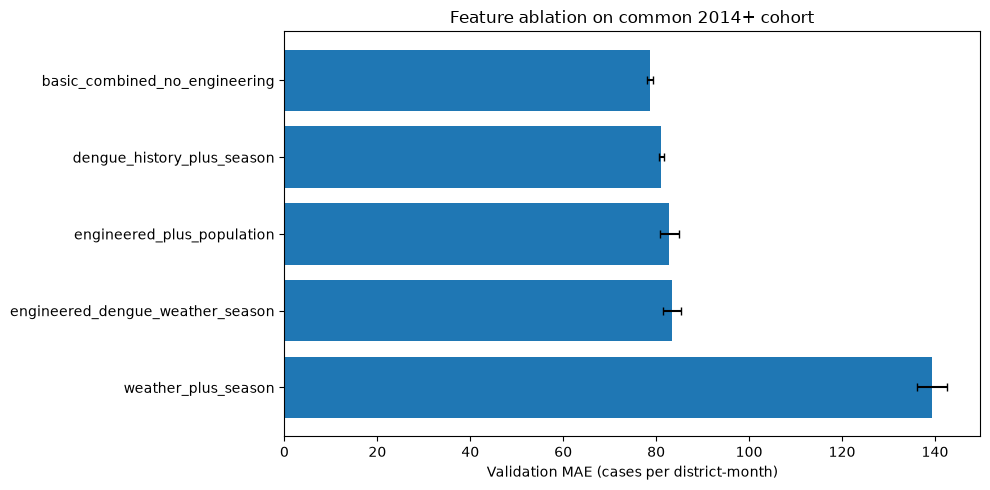

In [5]:
summary=(results.groupby('experiment',as_index=False)
 .agg(n_seeds=('seed','nunique'),MAE_mean=('MAE_cases','mean'),MAE_sd=('MAE_cases','std'),RMSE_mean=('RMSE_cases','mean'),RMSE_sd=('RMSE_cases','std'),bias_mean=('bias_cases','mean'))
 .sort_values('MAE_mean'))
display(summary)
fig,ax=plt.subplots(figsize=(10,5));ax.barh(summary['experiment'],summary['MAE_mean'],xerr=summary['MAE_sd'].fillna(0),capsize=3)
ax.invert_yaxis();ax.set(xlabel='Validation MAE (cases per district-month)',title='Feature ablation on common 2014+ cohort');fig.tight_layout()
fig.savefig(FIGS/'notebook17_ablation_validation_mae.png',dpi=160);plt.show()

## 6. Explicit contribution comparisons
Ablation answers the following **conditional** questions: does engineering help beyond basic contemporaneous predictors; does weather help beyond dengue history; does population help beyond engineered weather/dengue? Note: group sizes and correlated predictors complicate interpretation. Population here is a **level** covariate, not automatically a population-adjusted incidence target.

In [6]:
lookup=summary.set_index('experiment')['MAE_mean']
comparisons=[
 ('engineering_vs_basic','basic_combined_no_engineering','engineered_dengue_weather_season'),
 ('adding_weather_to_dengue','dengue_history_plus_season','engineered_dengue_weather_season'),
 ('adding_population','engineered_dengue_weather_season','engineered_plus_population')]
contrasts=pd.DataFrame([{'contrast':label,'reference':base,'candidate':candidate,
 'reference_MAE':float(lookup[base]),'candidate_MAE':float(lookup[candidate]),
 'MAE_improvement_cases_positive_is_better':float(lookup[base]-lookup[candidate])}
 for label,base,candidate in comparisons])
display(contrasts)

,contrast,reference,candidate,reference_MAE,candidate_MAE,MAE_improvement_cases_positive_is_better
0,engineering_vs_basic,basic_combined_no_engineering,engineered_dengue_weather_season,78.600190,83.452708,-4.852518
1,adding_weather_to_dengue,dengue_history_plus_season,engineered_dengue_weather_season,81.086002,83.452708,-2.366706
2,adding_population,engineered_dengue_weather_season,engineered_plus_population,83.452708,82.851227,0.601481


## 7. Save auditable outputs
These results **do not replace** the final frozen 2024 model. They are exploratory validation comparisons on a shorter common training cohort.

In [7]:
results.to_csv(TABLES/'notebook17_ablation_seed_metrics.csv',index=False)
summary.to_csv(TABLES/'notebook17_ablation_summary.csv',index=False)
contrasts.to_csv(TABLES/'notebook17_ablation_contrasts.csv',index=False)
predictions.to_csv(TABLES/'notebook17_ablation_validation_predictions.csv',index=False)
manifest={'protocol':'2014_plus_common_cohort_validation_only','train_end':'2021-12','validation':'2022-2023',
 'test_2024_accessed':False,'seeds':list(SEEDS),'architecture':'LSTM32-Dense16-Dropout-Dense1',
 'epochs_max':MAX_EPOCHS,'early_stopping_patience':PATIENCE,'feature_groups':{k:{'variant':v,'features':[(weather_names if v=='weather_only' else pop_names)[i] for i in inds]} for k,(v,inds) in experiments.items()},
 'warning':'Validation used for early stopping; 2024 not used for new model selection.'}
(METRICS/'notebook17_ablation_protocol.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Saved Notebook 17 tables, figure, and protocol. Interpret outcomes only after execution.')

Saved Notebook 17 tables, figure, and protocol. Interpret outcomes only after execution.


## 8. Interpretation for your research paper
- **If engineered features lower validation MAE:** they may improve one-month forecasting on this cohort.
- **If dengue+weather beats dengue-only:** weather adds predictive information beyond dengue history under this model and split.
- **If population adds little:** do not claim population is unimportant; the target, feature representation, and limited time coverage may matter.
- **If weather-only performs poorly:** it suggests weather alone is insufficient, not that weather has no association with dengue.

**Limitations:** this is a single chronological validation window, early stopping uses that window, and repeated seeds are not independent temporal holdouts. Do not call validation results an untouched test evaluation. Do not retune the published 2024 result using these outcomes.